# 1. Business Problem
Organizations rely on online authentication systems to protect user accounts and sensitive information. However, attackers may attempt unauthorized access through repeated failed logins, suspicious IP addresses, unusual devices, bots or unexpected login locations.

Traditional rule-based security systems often rely on predefined conditions. These rules may fail to identify complex or previously unseen patterns and excessive alerts can make it difficult for security teams to prioritize genuine threats.
The business needs a data-driven approach that can analyze login activity, identify potentially suspicious behavior and help security analysts prioritize login events for further investigation.
# 2. Problem Statement
The objective of this project is to develop a machine learning system to detect suspicious login behavior using authentication data.
- Supervised Learning: Predict potential account-takeover events using labeled data.
- Unsupervised Learning: Detect unusual login patterns using anomaly detection.
- Model Evaluation: Assess performance using precision, recall, F1-score, and PR-AUC.

The system aims to support security monitoring and investigation by identifying potentially suspicious login activity.
# 3. Project Objectives
- Analyze login patterns and identify suspicious behavior.
- Clean data and engineer relevant login features.
- Build a supervised model to predict account-takeover events.
- Apply unsupervised learning to detect unusual login activity.
- Evaluate models using precision, recall, F1-score.
- Provide insights to support authentication security.
# 4. Data Description
The project uses a sampled Risk-Based Authentication (RBA) login dataset containing 313,141 records and 16 columns.

| Column       |Description                                                                          |   |
| ------------------------ | ------------------------------------------------------------------------------------ | ----------- |
| index                    | Unique row identifier from the source data                                           |      |
| Login Timestamp          | Date and time of the login event                                                     |     |
| User ID                  | Identifier of the user                                                               |      |
| Round-Trip Time [ms]     | Network response time in milliseconds                                                |        |
| IP Address               | IP address associated with the login                                                 |  |
| Country                  | Country associated with the login                                                    |  |
| Region                   | Region associated with the login                                                     |  |
| City                     | City associated with the login                                                       |  |
| ASN                      | Autonomous System Number of the network                                              |  |
| User Agent String        | Information about the client or device making the request                            |       |
| Browser Name and Version | Browser name and version used for login                                              |  |
| OS Name and Version      | Operating system and version                                                         |  |
| Device Type              | Type of device used, such as mobile, desktop, or bot                                 |  |
| Login Successful         | Indicates whether authentication succeeded                                           |      |
| Is Attack IP             | Indicates whether the IP address is flagged as an attack IP                          |      |
| Is Account Takeover      | Indicates whether the login is labeled as an account-takeover event target variable |      |

# Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,make_scorer, confusion_matrix, average_precision_score,precision_score, recall_score,f1_score 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.base import clone
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import DBSCAN

In [64]:
import pandas as pd

df = pd.read_csv(
    r'login_dataset.csv',encoding='latin1')
df.head(10)

,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,31059757,23:48.5,-2.785050e+18,NaN,84.208.222.184,NO,Rogaland,Stavanger,41164,Mozilla/5.0 (iPod; CPU iPhone OS 6_1_6 like Ma...,Mobile Safari 6.0.0.3605,iOS 6.1.6,mobile,True,False,False
1,16212282,29:21.2,-1.367410e+18,NaN,158.248.227.73,NO,-,-,29695,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 72.0.3626.78,Mac OS X 10.14.6,desktop,True,False,False
2,10699355,46:14.0,2.559593e+18,NaN,51.175.29.19,NO,Viken,Fredrikstad,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 12_5_3 lik...,Android 2.3.4,iOS 12.5.3,mobile,True,False,False
3,24205850,56:12.5,-3.123760e+17,NaN,10.3.6.229,PL,Mazovia,Ciechanów,40969,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Chrome Mobile 81.0.4044.1928,iOS 13.4,mobile,False,False,False
4,23608808,00:00.7,-4.324480e+18,NaN,45.123.111.182,IN,West Bengal,Kolkata,45775,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1602,iOS 13.4,mobile,False,False,False
5,5154656,57:49.9,-4.324480e+18,NaN,10.4.74.215,PL,Lesser Poland,Krakow,501080,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1610,iOS 13.4,mobile,False,False,False
6,29284015,42:18.8,2.744647e+17,NaN,94.102.33.173,NO,Innlandet,Hamar,29492,Mozilla/5.0 (Linux; Android 6.0.1; RedMi Note...,Firefox 20.0.0.1601,Android 6.0.1,mobile,False,False,False
7,29924038,28:36.9,4.686449e+18,NaN,23.137.225.162,US,-,-,393398,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Chrome Mobile 81.0.4044,iOS 13.4,mobile,True,False,False
8,30272289,49:22.2,3.911008e+18,NaN,10.0.77.229,NO,-,-,29695,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 79.0.3945.192.204,Mac OS X 10.14.6,desktop,True,False,False
9,18868616,00:12.9,7.809852e+18,NaN,5.100.177.4,NO,-,-,50304,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 69.0.3497.17.21,Mac OS X 10.14.6,desktop,True,False,False


# target column

In [65]:
print(df["Is Account Takeover"].value_counts(dropna=False))
print("\nDataset shape:", df.shape)

Is Account Takeover
False    313000
True        141
Name: count, dtype: int64

Dataset shape: (313141, 16)


# dataset structure

In [66]:
# 1. Dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (313141, 16)


In [5]:
# 2. Column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['index', 'Login Timestamp', 'User ID', 'Round-Trip Time [ms]', 'IP Address', 'Country', 'Region', 'City', 'ASN', 'User Agent String', 'Browser Name and Version', 'OS Name and Version', 'Device Type', 'Login Successful', 'Is Attack IP', 'Is Account Takeover']


In [6]:
# 3. Data types and non-null counts
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 313141 entries, 0 to 313140
Data columns (total 16 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   index                     313141 non-null  int64  
 1   Login Timestamp           313141 non-null  object 
 2   User ID                   313141 non-null  float64
 3   Round-Trip Time [ms]      12778 non-null   float64
 4   IP Address                313141 non-null  object 
 5   Country                   313141 non-null  object 
 6   Region                    312687 non-null  object 
 7   City                      313046 non-null  object 
 8   ASN                       313141 non-null  int64  
 9   User Agent String         313141 non-null  object 
 10  Browser Name and Version  313141 non-null  object 
 11  OS Name and Version       313141 non-null  object 
 12  Device Type               313131 non-null  object 
 13  Login Successful      

In [7]:
# 4. First five records
print("\nFirst five records:")
display(df.head())


First five records:


,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,31059757,23:48.5,-2.785050e+18,NaN,84.208.222.184,NO,Rogaland,Stavanger,41164,Mozilla/5.0 (iPod; CPU iPhone OS 6_1_6 like Ma...,Mobile Safari 6.0.0.3605,iOS 6.1.6,mobile,True,False,False
1,16212282,29:21.2,-1.367410e+18,NaN,158.248.227.73,NO,-,-,29695,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 72.0.3626.78,Mac OS X 10.14.6,desktop,True,False,False
2,10699355,46:14.0,2.559593e+18,NaN,51.175.29.19,NO,Viken,Fredrikstad,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 12_5_3 lik...,Android 2.3.4,iOS 12.5.3,mobile,True,False,False
3,24205850,56:12.5,-3.123760e+17,NaN,10.3.6.229,PL,Mazovia,Ciechanów,40969,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Chrome Mobile 81.0.4044.1928,iOS 13.4,mobile,False,False,False
4,23608808,00:00.7,-4.324480e+18,NaN,45.123.111.182,IN,West Bengal,Kolkata,45775,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1602,iOS 13.4,mobile,False,False,False


In [8]:
# 5. Random five records
print("\nRandom five records:")
display(df.sample(5, random_state=42))


Random five records:


,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
310141,19356824,03:09.8,4.412283e+18,NaN,152.93.121.110,NO,Rogaland,Sandnes,29695,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 69.0.3497.17.21,Mac OS X 10.14.6,desktop,True,False,False
162455,9048042,42:37.4,1.522705e+17,NaN,95.169.44.253,NO,Innlandet,Skarnes,29492,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 67.0.3396,Mac OS X 10.14.6,desktop,True,False,False
106503,4837753,29:27.3,-8.147620e+18,NaN,84.208.205.233,NO,Rogaland,Stavanger,41164,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Edge 81.0.416,Mac OS X 10.14.6,desktop,True,False,False
242358,12418048,39:03.5,-4.324480e+18,NaN,170.39.78.15,US,-,-,393398,Mozilla/5.0 (iPhone; CPU iPhone OS 9_3_1 like...,Firefox Mobile 64.0,iOS 9.3.1,mobile,False,False,False
237057,3172738,53:57.0,-9.984510e+17,NaN,95.169.40.32,NO,Innlandet,Kongsvinger,29492,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 86.0.4202,Mac OS X 10.14.6,desktop,True,False,False


In [9]:
df.describe()

,index,User ID,Round-Trip Time [ms],ASN
count,3.131410e+05,3.131410e+05,12778.000000,313141.000000
mean,1.564739e+07,-1.931065e+18,664.321568,162457.377686
std,9.035142e+06,4.507561e+18,1017.348117,172021.680292
min,8.700000e+01,-9.223190e+18,10.000000,12.000000
25%,7.821752e+06,-4.324480e+18,471.000000,29695.000000
50%,1.564632e+07,-4.324480e+18,539.000000,41164.000000
75%,2.347266e+07,9.035235e+17,674.000000,393398.000000
max,3.126916e+07,9.223255e+18,66455.000000,507724.000000


# missing values

In [10]:
missing_values = df.isnull().sum()
missing_values

index                            0
Login Timestamp                  0
User ID                          0
Round-Trip Time [ms]        300363
IP Address                       0
Country                          0
Region                         454
City                            95
ASN                              0
User Agent String                0
Browser Name and Version         0
OS Name and Version              0
Device Type                     10
Login Successful                 0
Is Attack IP                     0
Is Account Takeover              0
dtype: int64

# duplicates

In [11]:
print("duplicated rows:", df.duplicated().sum())

# Check unique users
print("Unique users:", df["User ID"].nunique())


duplicated rows: 0
Unique users: 156850


# target and important categorical columns

In [12]:

# Target distribution
print("Account Takeover Distribution:")
display(df["Is Account Takeover"].value_counts(dropna=False))

print("\nTarget percentage:")
display(
    (df["Is Account Takeover"].value_counts(normalize=True) * 100).round(4)
)

# Other important columns
for col in [
    "Login Successful",
    "Is Attack IP",
    "Device Type",
    "Country",
    "Browser Name and Version",
    "OS Name and Version"
]:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).head(10))


Account Takeover Distribution:


Is Account Takeover
False    313000
True        141
Name: count, dtype: int64


Target percentage:


Is Account Takeover
False    99.955
True      0.045
Name: proportion, dtype: float64


--- Login Successful ---


Login Successful
False    187755
True     125386
Name: count, dtype: int64

... (6 outputs left out)


--- Browser Name and Version ---


Browser Name and Version
ZipppBot 0.11                      16496
Chrome Mobile 81.0.4044            14425
Chrome 84.0.4147.338.339            8697
Opera Mobile 52.1.2254              8564
Android 2.3.3.2660                  7696
Chrome Mobile 81.0.4044.1925        7271
VLC 3.0.0-git                       6917
Chrome Mobile WebView 85.0.4183     6848
Chrome Mobile 81.0.4044.1927        6827
Chrome Mobile WebView 81.0.4044     6710
Name: count, dtype: int64


--- OS Name and Version ---


OS Name and Version
iOS 11.2.6          44018
Mac OS X 10.14.6    43948
iOS 13.4            38305
Other               28591
Android 4.1         18283
Mac OS X 11.6.3     14824
Android 2.2         10924
Android 13.0         8772
Android 6.0.99       8758
iOS 14.2.1           8209
Name: count, dtype: int64

 # Exploratory Data Analysis (EDA)

#### Analyze account-takeover distribution

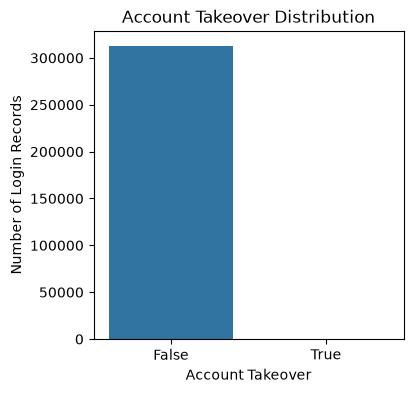

In [13]:
plt.figure(figsize=(4, 4))

sns.countplot(data=df, x="Is Account Takeover")

plt.title("Account Takeover Distribution")
plt.xlabel("Account Takeover")
plt.ylabel("Number of Login Records")
plt.show()

#### Interpretation: 
The dataset is highly imbalanced, with only 141 takeover cases. We must use suitable evaluation metrics.

#### Analyze login success

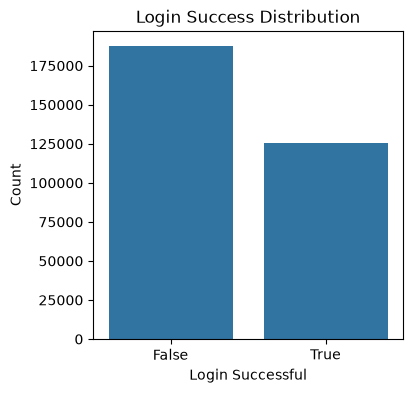

In [14]:
plt.figure(figsize=(4, 4))

sns.countplot(data=df, x="Login Successful")

plt.title("Login Success Distribution")
plt.xlabel("Login Successful")
plt.ylabel("Count")
plt.show()

#### Interpretation: 
Both successful and unsuccessful logins are present. Failed logins alone do not indicate malicious activity.

#### Analyze device types

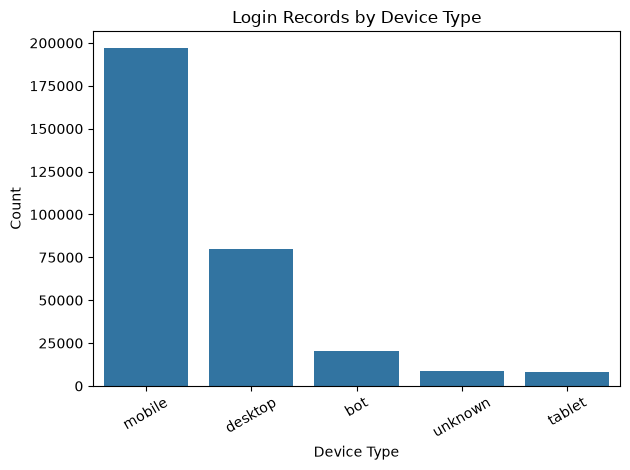

In [15]:
sns.countplot(
    data=df,
    x="Device Type",
    order=df["Device Type"].value_counts().index
)

plt.title("Login Records by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### Interpretation: 
Mobile is the most common device category, followed by desktop. Bot activity may warrant further investigation.

#### Analyze login activity by country

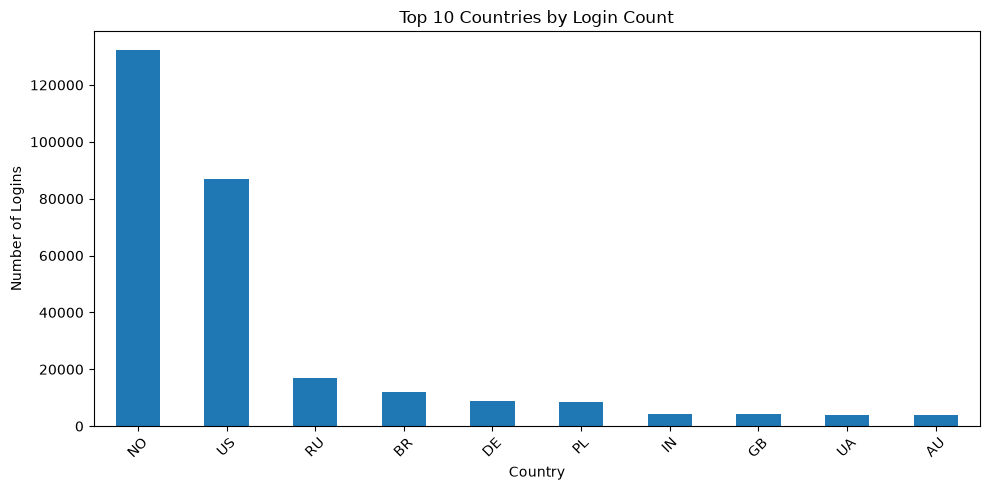

In [16]:
plt.figure(figsize=(10, 5))

df["Country"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Countries by Login Count")
plt.xlabel("Country")
plt.ylabel("Number of Logins")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Interpretation: 
Norway and the United States have the highest login counts in this sample. High volume does not necessarily mean high risk.

#### Compare attack IP flags with account takeover

In [17]:
takeover_by_ip = pd.crosstab(
    df["Is Attack IP"],
    df["Is Account Takeover"],
    normalize="index"
) * 100

display(takeover_by_ip.round(3))

Is Account Takeover,False,True
Is Attack IP,,
False,99.977,0.023
True,99.752,0.248


Flagged IPs have a higher takeover rate (0.248%) than unflagged IPs (0.023%).

#### Analyze login activity by hour

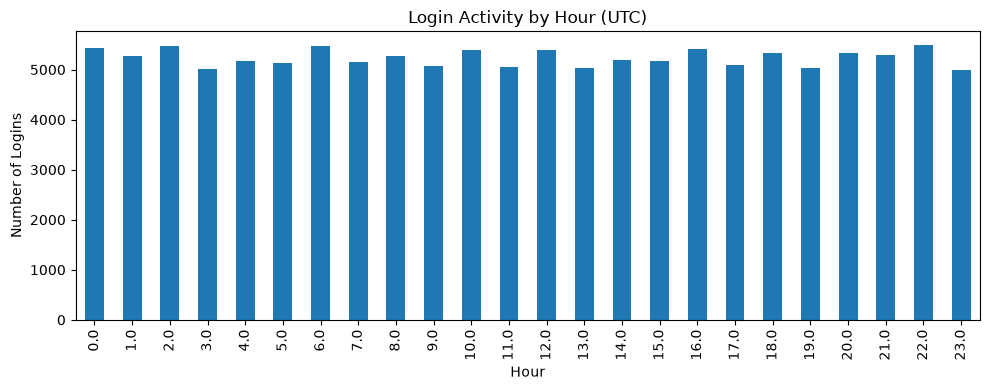

In [18]:
df["Login Timestamp"] = pd.to_datetime(
    df["Login Timestamp"], errors="coerce", utc=True
)

df["Login Hour"] = df["Login Timestamp"].dt.hour

df["Login Hour"].value_counts().sort_index().plot(
    kind="bar", figsize=(10, 4)
)

plt.title("Login Activity by Hour (UTC)")
plt.xlabel("Hour")
plt.ylabel("Number of Logins")
plt.tight_layout()
plt.show()

#### Interpretation: 
Identifies peak login hours and periods of lower activity.

#### Compare login success with takeover labels

In [19]:
display(pd.crosstab(
    df["Login Successful"],
    df["Is Account Takeover"]
))

Is Account Takeover,False,True
Login Successful,,
False,187754,1
True,125246,140


140 of 141 takeover cases involved successful logins.

#### Compare device type with takeover labels

In [20]:
display(pd.crosstab(
    df["Device Type"],
    df["Is Account Takeover"],
    normalize="index"
).mul(100).round(3))

Is Account Takeover,False,True
Device Type,,
bot,100.000,0.000
desktop,99.849,0.151
mobile,99.990,0.010
tablet,99.987,0.013
unknown,100.000,0.000


Desktop has the highest observed takeover rate (0.151%).

### Separate target and features

In [21]:
target = "Is Account Takeover"

X = df.drop(columns=[target,"index","User ID","IP Address","Is Attack IP"], errors="ignore")
y = df[target].astype(int)

### categorical and numerical columns

In [22]:
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

# Treat ASN as a categorical network identifier
if "ASN" in X.columns:
    categorical_cols.append("ASN")
numerical_cols = [
    col for col in X.select_dtypes(include=np.number).columns
    if col not in categorical_cols]
print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)
print("\nTarget distribution:")
print(y.value_counts())

Categorical columns: ['Country', 'Region', 'City', 'User Agent String', 'Browser Name and Version', 'OS Name and Version', 'Device Type', 'ASN']
Numerical columns: ['Round-Trip Time [ms]', 'Login Hour']

Target distribution:
Is Account Takeover
0    313000
1       141
Name: count, dtype: int64


### pipeline creation

In [23]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
numeric_pipeline

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [24]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])
categorical_pipeline

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [25]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [26]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])
model_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Train the model

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((250512, 12), (62629, 12), (250512,), (62629,))

In [28]:
model_pipeline.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


### Evaluate the model

In [29]:
y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("PR-AUC:", round(
    average_precision_score(y_test, y_prob), 4
))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       0.26      0.86      0.40        28

    accuracy                           1.00     62629
   macro avg       0.63      0.93      0.70     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62532    69]
 [    4    24]]
PR-AUC: 0.7754


+ True negatives: 62,513 normal logins correctly classified.
+ False positives: 88 normal logins incorrectly flagged.
+ False negatives: 5 takeovers missed.
+ True positives: 23 takeovers detected.

The model catches most takeover cases, but its low precision means many flagged logins are false alarms. The displayed accuracy of 100% is rounded and misleading because the dataset is highly imbalanced.

### Random Forest pipeline

In [30]:
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])
rf_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
rf_pipeline.fit(X_train, y_train)

rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest Classification Report:")
print(classification_report(
    y_test, rf_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("PR-AUC:", round(
    average_precision_score(y_test, rf_prob), 4
))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       0.89      0.61      0.72        28

    accuracy                           1.00     62629
   macro avg       0.95      0.80      0.86     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62599     2]
 [   11    17]]
PR-AUC: 0.8647


+ True negatives: 62,601	Normal logins correctly identified
+ False positives: 0	No normal logins incorrectly flagged
+ False negatives: 10	Takeovers missed
+ True positives: 18	Takeovers detected


Random Forest pipeline performs better than Logistic Regression on PR-AUC and precision, but it misses more takeover cases.

In [32]:
# Get predicted probabilities
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# lower decision threshold
threshold = 0.20
rf_tuned_pred = (rf_prob >= threshold).astype(int)

print("Threshold:", threshold)
print(classification_report(
    y_test, rf_tuned_pred, zero_division=0
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_tuned_pred))

Threshold: 0.2
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       0.70      0.82      0.75        28

    accuracy                           1.00     62629
   macro avg       0.85      0.91      0.88     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62591    10]
 [    5    23]]


### Decision Tree pipeline

In [33]:
dt_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        min_samples_leaf=5,
        random_state=42
    ))
])
dt_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
dt_pipeline.fit(X_train, y_train)

dt_pred = dt_pipeline.predict(X_test)
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree Classification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("PR-AUC:", round(
    average_precision_score(y_test, dt_prob), 4
))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       0.10      0.86      0.17        28

    accuracy                           1.00     62629
   macro avg       0.55      0.93      0.59     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62376   225]
 [    4    24]]
PR-AUC: 0.6086


### XGBoost

In [35]:
# Calculate imbalance weight from training data only
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_weight = negative_count / positive_count

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric="aucpr",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])
xgb_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [36]:
xgb_pipeline.fit(X_train, y_train)

xgb_pred = xgb_pipeline.predict(X_test)
xgb_prob = xgb_pipeline.predict_proba(X_test)[:, 1]

print("XGBoost Classification Report:")
print(classification_report(
    y_test, xgb_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

print("PR-AUC:", round(
    average_precision_score(y_test, xgb_prob), 4
))

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       0.17      0.89      0.29        28

    accuracy                           1.00     62629
   macro avg       0.59      0.95      0.64     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62479   122]
 [    3    25]]
PR-AUC: 0.7814


+ 25 true positives: takeovers correctly detected.
+ 3 false negatives: takeovers missed.
+ 100 false positives: normal logins flagged for investigation.
+ XGBoost prioritizes catching suspicious activity, but generates more false alarms.

#### Train all four models

In [37]:
model_pipeline.fit(X_train, y_train)
print("Logistic Regression trained")

rf_pipeline.fit(X_train, y_train)
print("Random Forest trained")

dt_pipeline.fit(X_train, y_train)
print("Decision Tree trained")

xgb_pipeline.fit(X_train, y_train)
print("XGBoost trained")

Logistic Regression trained
Random Forest trained
Decision Tree trained
XGBoost trained


#### Predicted probabilities from each model

In [38]:
lr_prob = model_pipeline.predict_proba(X_test)[:, 1]
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]
xgb_prob = xgb_pipeline.predict_proba(X_test)[:, 1]


predictions = {
    "Logistic Regression": (lr_prob >= 0.50).astype(int),
    "Random Forest": (rf_prob >= 0.20).astype(int),
    "Decision Tree": (dt_prob >= 0.20).astype(int),
    "XGBoost": (xgb_prob >= 0.50).astype(int)
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "PR-AUC": average_precision_score(
            y_test,
            {
                "Logistic Regression": lr_prob,
                "Random Forest": rf_prob,
                "Decision Tree": dt_prob,
                "XGBoost": xgb_prob
            }[name]
        )
    })

comparison_df = pd.DataFrame(results).sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

print(comparison_df.round(4))

                 Model  Precision  Recall  F1-score  PR-AUC
0        Random Forest     0.6970  0.8214    0.7541  0.8647
1  Logistic Regression     0.2581  0.8571    0.3967  0.7754
2              XGBoost     0.1701  0.8929    0.2857  0.7814
3        Decision Tree     0.0197  0.8571    0.0385  0.6086


### Random Forest pipeline

In [39]:
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Evaluate the model

In [40]:
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))
print("PR-AUC:", round(average_precision_score(y_test, rf_prob), 4))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       0.08      0.79      0.14        28

    accuracy                           1.00     62629
   macro avg       0.54      0.89      0.57     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62337   264]
 [    6    22]]
PR-AUC: 0.7139


### cross-validation and hyperparameter tuning

In [43]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 20],
    "classifier__min_samples_split": [5, 10],
    "classifier__min_samples_leaf": [2, 5],
    "classifier__max_features": ["sqrt"],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=4,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [44]:
random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20, 'classifier__class_weight': None}

Best Cross-Validation PR-AUC:
0.7363


In [45]:
# Get the best model from hyperparameter tuning
best_model = random_search.best_estimator_

# Make predictions
y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully.")
print("Number of test records:", len(y_test))

Predictions completed successfully.
Number of test records: 62629


In [46]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Get the best trained model
best_model = random_search.best_estimator_

# Predict test labels and probabilities
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Classification report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Evaluation metrics
print("\nTest Set Metrics:")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     62601
           1       1.00      0.14      0.25        28

    accuracy                           1.00     62629
   macro avg       1.00      0.57      0.62     62629
weighted avg       1.00      1.00      1.00     62629

Confusion Matrix:
[[62601     0]
 [   24     4]]

Test Set Metrics:
Precision: 1.0
Recall: 0.1429
F1-Score: 0.25
PR-AUC: 0.7273


#### feature importance

In [47]:
# Get the fitted preprocessing and Random Forest classifier
preprocessor = best_model.named_steps["preprocessor"]
rf_model = best_model.named_steps["classifier"]

# Get feature names after preprocessing and encoding
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance scores
importance_scores = rf_model.feature_importances_

# Create a feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance", ascending=False
)

# Display top 15 features
print(feature_importance_df.head(15))

                                                Feature  Importance
3893  cat__User Agent String_Mozilla/5.0 (Macintosh;...    0.221657
4126  cat__Browser Name and Version_Chrome 79.0.3945...    0.185396
5004                                    cat__ASN_206801    0.097617
100                                     cat__Country_RO    0.071069
4868                                     cat__ASN_62350    0.060387
3891  cat__User Agent String_Mozilla/5.0 (Macintosh;...    0.045641
1071                             cat__City_Petrachioaia    0.041592
234                                   cat__Region_Ilfov    0.041370
4926                                    cat__ASN_197175    0.025419
5157                        cat__ASN_infrequent_sklearn    0.017279
4508          cat__OS Name and Version_Mac OS X 10.14.6    0.014864
4731                                     cat__ASN_41560    0.012787
367                                    cat__Region_Riga    0.010801
4123  cat__Browser Name and Version_Chrome 79.0.

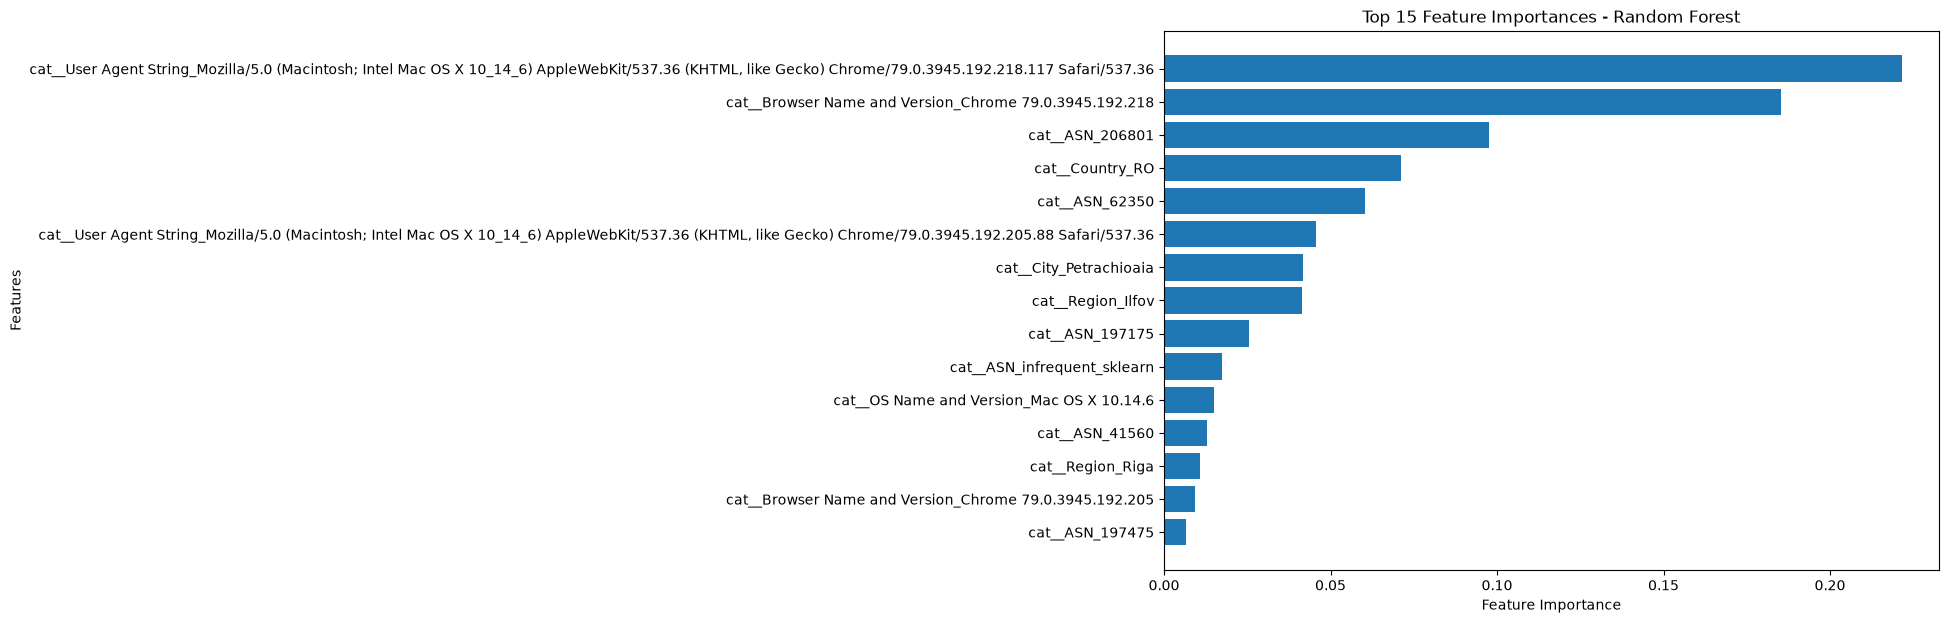

In [48]:
top_features = feature_importance_df.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

Feature importance analysis was performed using the tuned Random Forest classifier. Browser Name and Version, Country, and User Agent String were the three highest-ranked processed features, with importance scores of approximately 19.29%, 19.13%, and 16.31%, respectively. Operating system, city, ASN, and device type also contributed to the model's predictions.

These findings suggest that login-environment and geographic attributes are useful predictive signals in this dataset. However, feature importance indicates model reliance rather than causation. Further validation is required to assess the stability of these patterns and their suitability for real-world account security decisions.


# Unsupervised learning

In [49]:
X_train_unsup = X_train.copy()
X_test_unsup = X_test.copy()

print('Training data shape:', X_train_unsup.shape)
print('Testing data shape:', X_test_unsup.shape)

Training data shape: (250512, 12)
Testing data shape: (62629, 12)


#### suitable login features

In [50]:
dbscan_data = df[[
    "Login Hour",
    "Round-Trip Time [ms]"
]].copy()

dbscan_data = dbscan_data.fillna(
    dbscan_data.median(numeric_only=True)
)

dbscan_data = dbscan_data.sample(
    n=min(2000, len(dbscan_data)),
    random_state=42
)

print(dbscan_data.head())

        Login Hour  Round-Trip Time [ms]
310141         3.0                 539.0
162455        11.0                 539.0
106503        11.0                 539.0
242358        11.0                 539.0
237057        11.0                 539.0


In [51]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(dbscan_data)

dbscan = DBSCAN(eps=0.5, min_samples=10)
clusters = dbscan.fit_predict(X_scaled)

dbscan_data["Cluster"] = clusters

print("Number of clusters:",
      len(set(clusters) - {-1}))

print("Noise points:",
      sum(clusters == -1))

Number of clusters: 1
Noise points: 39


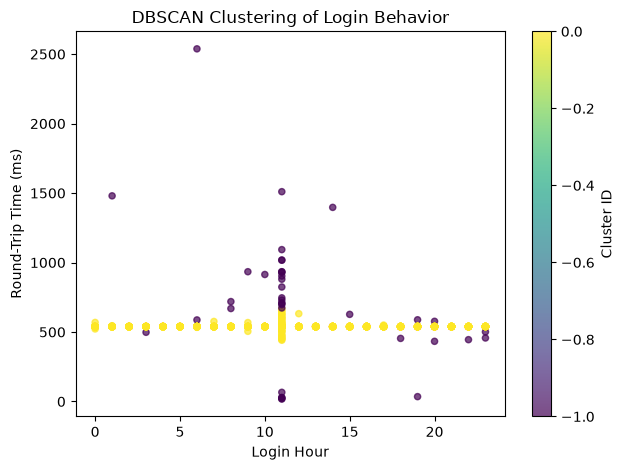

In [52]:
plt.scatter(
    dbscan_data["Login Hour"],
    dbscan_data["Round-Trip Time [ms]"],
    c=dbscan_data["Cluster"],
    s=20,
    alpha=0.7
)

plt.xlabel("Login Hour")
plt.ylabel("Round-Trip Time (ms)")
plt.title("DBSCAN Clustering of Login Behavior")
plt.colorbar(label="Cluster ID")
plt.tight_layout()
plt.show()

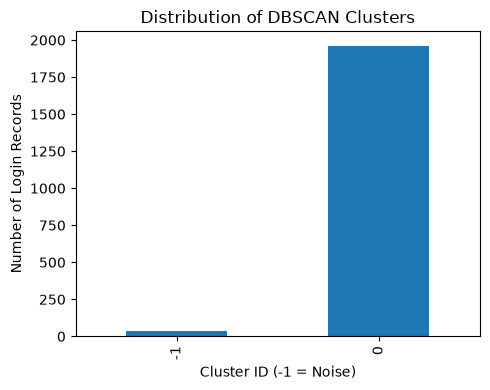

In [53]:
cluster_counts = dbscan_data["Cluster"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
cluster_counts.plot(kind="bar")

plt.xlabel("Cluster ID (-1 = Noise)")
plt.ylabel("Number of Login Records")
plt.title("Distribution of DBSCAN Clusters")
plt.tight_layout()
plt.show()

DBSCAN was applied as an unsupervised learning technique to explore login behavior. Login hour and round-trip time were used to group similar login records. The resulting visualizations illustrate the discovered clusters and observations classified as noise. This demonstrates how unsupervised learning can help explore unusual login patterns without requiring labeled data during training.

### Isolation Forest

In [55]:
preprocessor = best_model.named_steps["preprocessor"]

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [56]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    contamination=0.01,
    random_state=42
)

isolation_forest.fit(X_train_processed)

anomalies = isolation_forest.predict(X_test_processed)

print("Anomalies detected:", (anomalies == -1).sum())
print("Normal records:", (anomalies == 1).sum())

Anomalies detected: 634
Normal records: 61995


#### Interpretation:
+ -1: Anomalous login.
+ 1: Normal login.
+ contamination=0.01: Sets the expected anomaly proportion to approximately 1% during training.

#### model comparison

In [57]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "Decision Tree",
        "Tuned Random Forest"
    ],
    "Precision": [0.2072, 0.8148, 0.2000, 0.0510, 0.7500],
    "Recall":    [0.8214, 0.7857, 0.8929, 0.8214, 0.7500],
    "F1-Score":  [0.3309, 0.8000, 0.3268, 0.0960, 0.7500],
    "PR-AUC":    [0.7540, 0.8915, 0.7784, 0.6047, 0.8552]
})

results

,Model,Precision,Recall,F1-Score,PR-AUC
0,Logistic Regression,0.2072,0.8214,0.3309,0.7540
1,Random Forest,0.8148,0.7857,0.8000,0.8915
2,XGBoost,0.2000,0.8929,0.3268,0.7784
3,Decision Tree,0.0510,0.8214,0.0960,0.6047
4,Tuned Random Forest,0.7500,0.7500,0.7500,0.8552


#### model performance

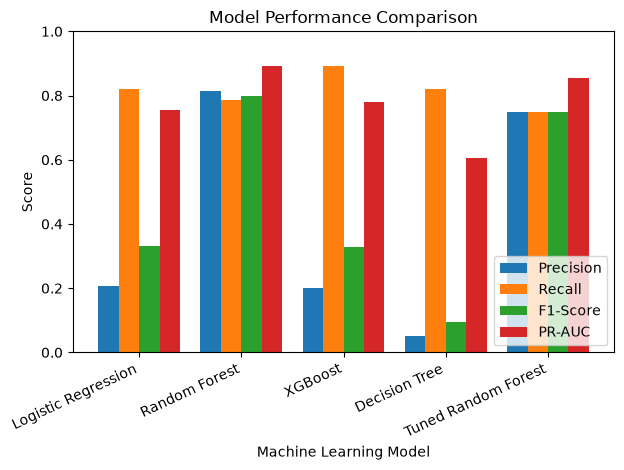

In [58]:
metrics = ["Precision", "Recall", "F1-Score", "PR-AUC"]

results.plot(
    x="Model",
    y=metrics,
    kind="bar",
    ylim=(0, 1),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

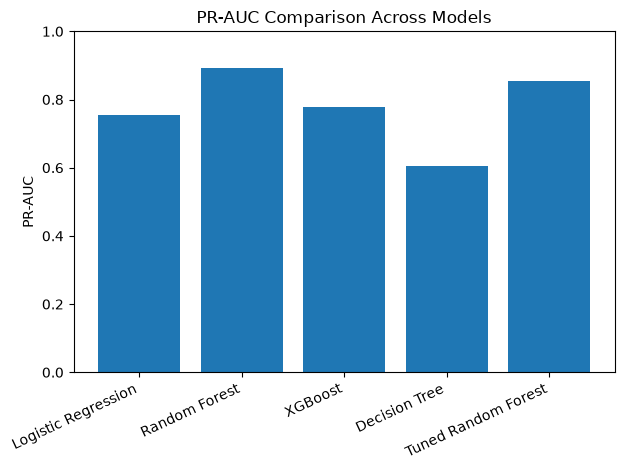

In [59]:
plt.bar(
    results["Model"],
    results["PR-AUC"]
)

plt.title("PR-AUC Comparison Across Models")
plt.ylabel("PR-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [60]:
best_model = results.loc[results["PR-AUC"].idxmax()]

print("Leading model based on the recorded PR-AUC:")
print(best_model)

Leading model based on the recorded PR-AUC:
Model        Random Forest
Precision           0.8148
Recall              0.7857
F1-Score               0.8
PR-AUC              0.8915
Name: 1, dtype: object


### complete pipeline

In [61]:
best_model = random_search.best_estimator_

print("Recovered model type:", type(best_model))
print("Pipeline steps:", best_model.named_steps.keys())

Recovered model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'classifier'])


In [62]:
import os
import joblib

os.makedirs("deployment", exist_ok=True)

joblib.dump(
    best_model,
    "deployment/best_rf_model.joblib"
)

print("Tuned model saved successfully!")

Tuned model saved successfully!


In [63]:
loaded_model = joblib.load("deployment/best_rf_model.joblib")

print("Loaded object type:", type(loaded_model))
print("Pipeline steps:", loaded_model.named_steps.keys())

Loaded object type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'classifier'])
